<a href="https://colab.research.google.com/github/Fardan777/Hasil-Laporan-Praktikum-AVD/blob/main/Kelompok_Dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [27]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df_emas = pd.read_csv('/content/Gold Price (2013-2023).csv')

# Clean & convert format angka dan tanggal jika diperlukan
# Menghapus koma pada angka (contoh: "1,900.50" -> 1900.50)
for col in ['Price', 'Open', 'High', 'Low']:
    if col in df_emas.columns and df_emas[col].dtype == 'object':
        df_emas[col] = df_emas[col].astype(str).str.replace(',', '').astype(float)

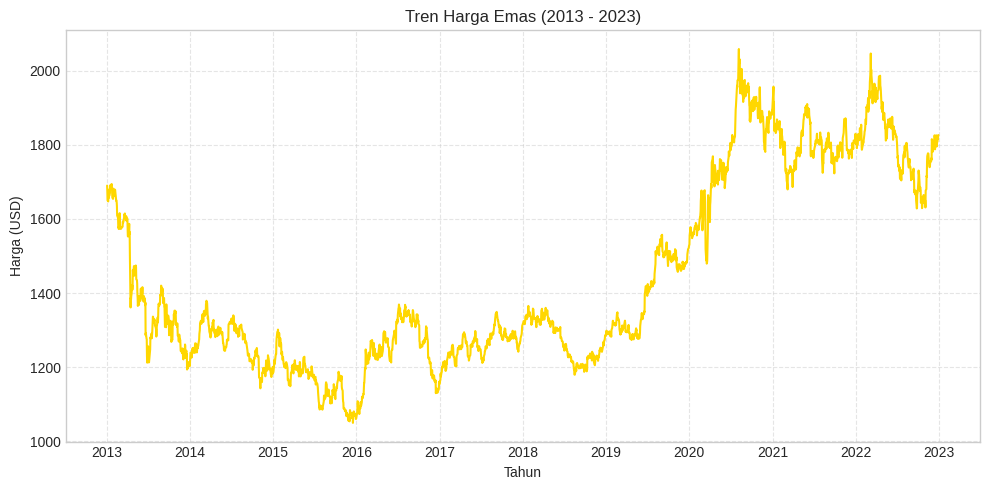

In [28]:
# 1. Konversi Kolom Date
if 'Date' in df_emas.columns:
    df_emas['Date'] = pd.to_datetime(df_emas['Date'])
    df_emas = df_emas.sort_values('Date')

    # Visualisasi Tren Harga Emas (Line Plot)
    plt.figure(figsize=(10, 5))
    plt.plot(df_emas['Date'], df_emas['Price'], color='gold', linewidth=1.5)
    plt.title('Tren Harga Emas (2013 - 2023)')
    plt.xlabel('Tahun')
    plt.ylabel('Harga (USD)')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

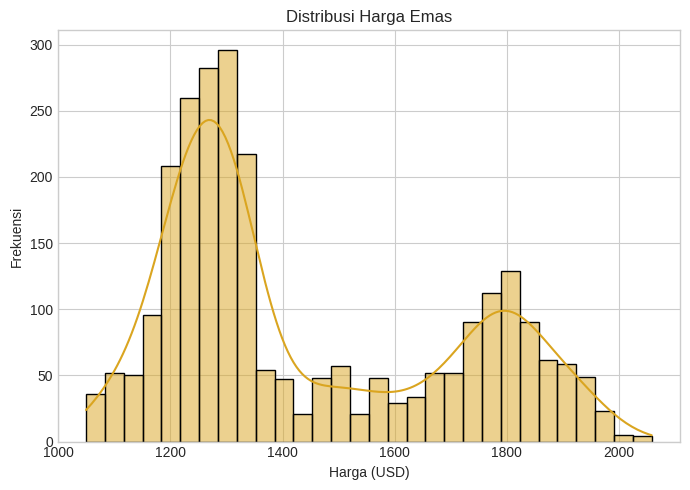

In [29]:
# 2. Visualisasi Distribusi Harga (Histogram)
if 'Price' in df_emas.columns:
    plt.figure(figsize=(7, 5))
    sns.histplot(df_emas['Price'], bins=30, kde=True, color='goldenrod')
    plt.title('Distribusi Harga Emas')
    plt.xlabel('Harga (USD)')
    plt.ylabel('Frekuensi')
    plt.tight_layout()
    plt.show()

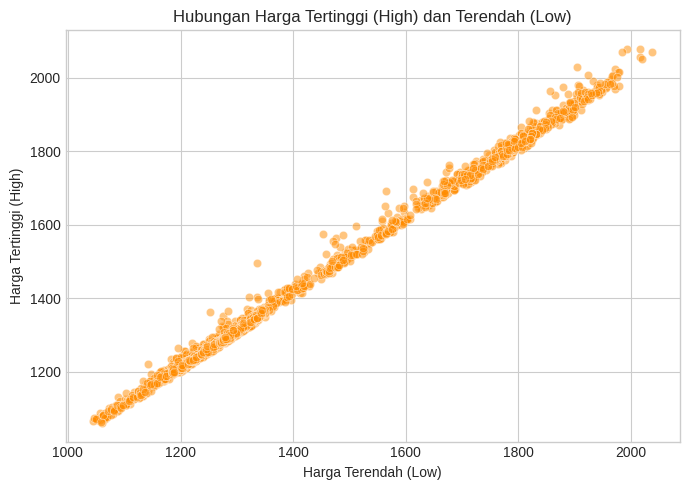

In [30]:
# 3. Visualisasi Hubungan High vs Low (Scatter Plot)
if 'High' in df_emas.columns and 'Low' in df_emas.columns:
    plt.figure(figsize=(7, 5))
    sns.scatterplot(data=df_emas, x='Low', y='High', alpha=0.5, color='darkorange')
    plt.title('Hubungan Harga Tertinggi (High) dan Terendah (Low)')
    plt.xlabel('Harga Terendah (Low)')
    plt.ylabel('Harga Tertinggi (High)')
    plt.tight_layout()
    plt.show()

In [31]:
print("--- 1. Data Kosong & Duplikat ---")
print("Data Kosong:\n", df_emas.isnull().sum())
print("Data Duplikat:", df_emas.duplicated().sum())

print("\n--- 2. Deteksi Outlier dengan Aturan IQR ---")
Q1 = df_emas['Price'].quantile(0.25)
Q3 = df_emas['Price'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df_emas[(df_emas['Price'] < lower_bound) | (df_emas['Price'] > upper_bound)]
print(f"Q1: {Q1:.2f} | Q3: {Q3:.2f} | IQR: {IQR:.2f}")
print(f"Batas Atas Outlier: {upper_bound:.2f}")
print(f"Jumlah Potensi Outlier: {len(outliers)} data")

--- 1. Data Kosong & Duplikat ---
Data Kosong:
 Date        0
Price       0
Open        0
High        0
Low         0
Vol.        5
Change %    0
dtype: int64
Data Duplikat: 0

--- 2. Deteksi Outlier dengan Aturan IQR ---
Q1: 1244.20 | Q3: 1713.95 | IQR: 469.75
Batas Atas Outlier: 2418.57
Jumlah Potensi Outlier: 0 data


/tmp/ipykernel_9178/1367643547.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=avg_yearly, x='Year', y='Price', ax=axes[0, 1], palette='YlOrBr')


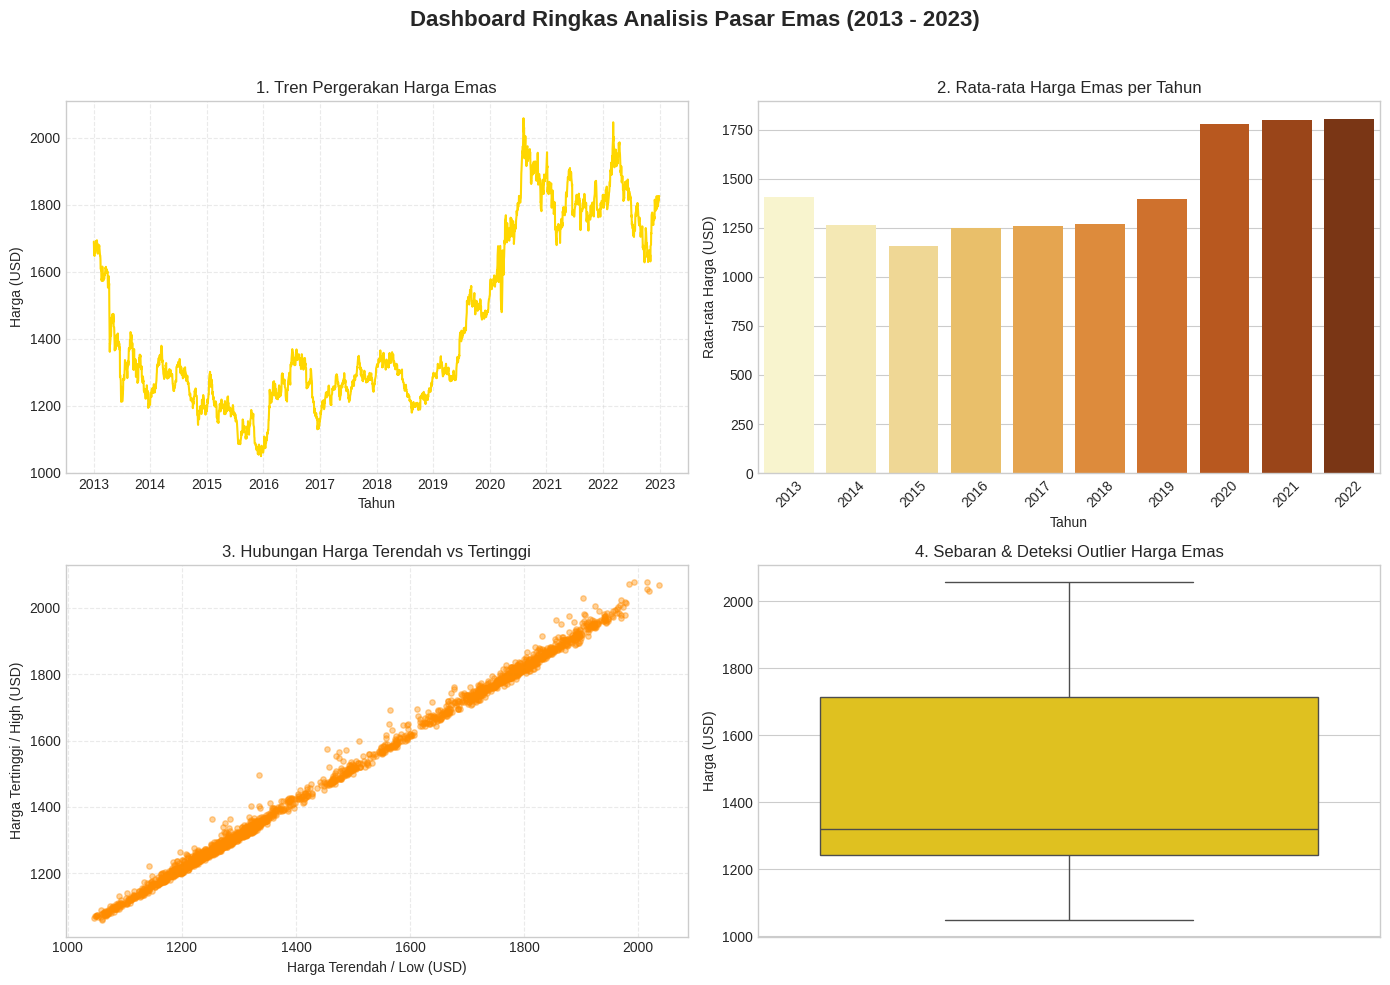

In [32]:
df_emas['Year'] = df_emas['Date'].dt.year
avg_yearly = df_emas.groupby('Year')['Price'].mean().reset_index()

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Dashboard Ringkas Analisis Pasar Emas (2013 - 2023)', fontsize=16, fontweight='bold')

# Grafik 1: Line Plot (Jenis 1)
axes[0, 0].plot(df_emas['Date'], df_emas['Price'], color='gold', linewidth=1.5)
axes[0, 0].set_title('1. Tren Pergerakan Harga Emas')
axes[0, 0].set_xlabel('Tahun')
axes[0, 0].set_ylabel('Harga (USD)')
axes[0, 0].grid(True, linestyle='--', alpha=0.4)

# Grafik 2: Bar Plot (Jenis 2)
sns.barplot(data=avg_yearly, x='Year', y='Price', ax=axes[0, 1], palette='YlOrBr')
axes[0, 1].set_title('2. Rata-rata Harga Emas per Tahun')
axes[0, 1].set_xlabel('Tahun')
axes[0, 1].set_ylabel('Rata-rata Harga (USD)')
axes[0, 1].tick_params(axis='x', rotation=45)

# Grafik 3: Scatter Plot (Jenis 3)
axes[1, 0].scatter(df_emas['Low'], df_emas['High'], alpha=0.4, color='darkorange', s=15)
axes[1, 0].set_title('3. Hubungan Harga Terendah vs Tertinggi')
axes[1, 0].set_xlabel('Harga Terendah / Low (USD)')
axes[1, 0].set_ylabel('Harga Tertinggi / High (USD)')
axes[1, 0].grid(True, linestyle='--', alpha=0.4)

# Grafik 4: Boxplot (Jenis 4 - Outlier)
sns.boxplot(y=df_emas['Price'], ax=axes[1, 1], color='gold')
axes[1, 1].set_title('4. Sebaran & Deteksi Outlier Harga Emas')
axes[1, 1].set_ylabel('Harga (USD)')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [33]:
#Berdasarkan analisis pergerakan harga emas periode 2013–2023, emas terbukti secara konsisten berfungsi sebagai instrumen pelindung nilai (safe-haven) yang tangguh. Meskipun sempat mengalami tren datar pada rentang 2013–2018, harga emas mencatatkan akselerasi pertumbuhan signifikan sejak pertengahan 2019 hingga 2023. Korelasi linier yang kuat antara nilai High dan Low harian mengonfirmasi likuiditas pasar yang stabil tanpa anomali fluktuasi ekstrem.   Rekomendasi Strategis:Alokasi Portofolio Defensive: Perusahaan disarankan mengalokasikan 10%–15% dana cadangan ke aset emas guna melindungi neraca keuangan dari risiko inflasi dan ketidakpastian makroekonomi global.   Metode Pembelian Bertahap (Dollar-Cost Averaging): Pembelian bertahap secara berkala lebih direkomendasikan saat harga mendekati area kuartil bawah ($Q1 \approx \text{USD } 1.241$), alih-alih melakukan lump-sum di area puncak (upper bound).   Manajemen Volatilitas: Rentang interkuartil ($IQR = 483,70$) menunjukkan fluktuasi harga yang cukup lebar dalam jangka menengah. Investor jangka pendek perlu menetapkan batas stop-loss yang memadai agar tidak terpengaruh oleh penyesuaian harga harian.   Dengan menerapkan strategi lindung nilai yang disiplin, portofolio keuangan perusahaan dapat menjaga ketahanan nilai aset sekaligus mengoptimalkan imbal hasil jangka panjang saat kondisi ekonomi bergejolak